In [1]:
from lights.plotting import setup_style
from lights.constants import mB, mK, mKs
from lights.form_factors import aK_vals_GRDV, aKs_vals_GRDV, aK_cov_GRDV, aKs_cov_GRDV, a_vals_gen
from lights.branching_fractions import K, KS, dBdqsq_SM, dBdqsq_BKphiphi, dBdqsq_BKpsipsi

import numpy as np
import numpy.random as npr
from scipy.integrate import quad
import matplotlib.pyplot as plt
cmap = plt.get_cmap("tab10")

setup_style()

In [2]:
BR_SM = quad(lambda qsq: dBdqsq_SM(qsq)[K], 1e-12, (mB - mK)**2)[0]
BR_psipsi = quad(lambda qsq: dBdqsq_BKpsipsi(qsq, 0.6, [1.,1.,0.,0.,0.,0.,0.,0.,0.,0.], 1e4)[K], (4*0.6**2), (mB - mK)**2)[0]
BR_SM, BR_psipsi

(4.904149612207374e-06, 9.596606009134639e-06)

In [ ]:
# Form factor toys (reproducible: fixed seed)
a_vals_r = a_vals_gen(10000, rng = 1)

qsq_vals = np.linspace(0.0001, (mB - mK)**2, 200)

dBdqsq_SM_BK_vals, dBdqsq_SM_BKs_vals = [], []
dBdqsq_psipsi_BK_vals = []

for a_vals in a_vals_r:
    # a_vals must be passed by keyword: the next positional argument of these functions is is_ident
    SM_rates = dBdqsq_SM(qsq_vals, a_vals = a_vals)
    dBdqsq_SM_BK_vals.append(SM_rates[K])
    dBdqsq_SM_BKs_vals.append(SM_rates[KS])
    dBdqsq_psipsi_BK_vals.append(dBdqsq_BKpsipsi(qsq_vals, 0.6, [1.,1.,0.,0.,0.,0.,0.,0.,0.,0.], 1e4, a_vals = a_vals)[K])

dBdqsq_SM_BK_vals_means = np.mean(dBdqsq_SM_BK_vals, axis = 0)
dBdqsq_SM_BK_vals_std = np.std(dBdqsq_SM_BK_vals, axis = 0)

dBdqsq_SM_BKs_vals_means = np.mean(dBdqsq_SM_BKs_vals, axis = 0)
dBdqsq_SM_BKs_vals_std = np.std(dBdqsq_SM_BKs_vals, axis = 0)

dBdqsq_psipsi_BK_vals_means = np.mean(dBdqsq_psipsi_BK_vals, axis = 0)
dBdqsq_psipsi_BK_vals_std = np.std(dBdqsq_psipsi_BK_vals, axis = 0)

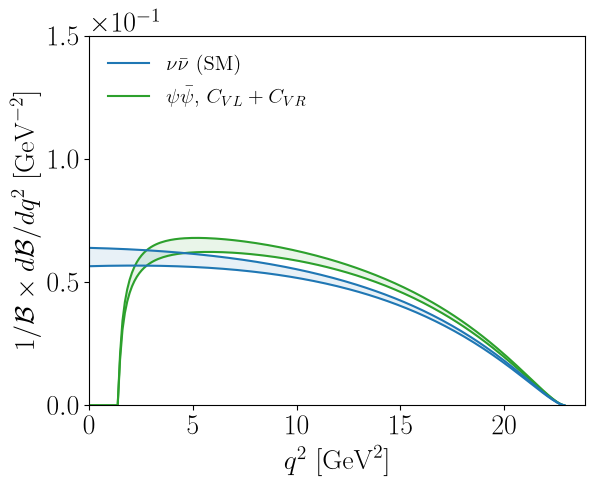

In [4]:
fig, axes = plt.subplots(nrows=1, ncols=1)

tot3, = axes.plot(qsq_vals, (dBdqsq_psipsi_BK_vals_means + dBdqsq_psipsi_BK_vals_std)/BR_psipsi, color=cmap(2));
axes.plot(qsq_vals, (dBdqsq_psipsi_BK_vals_means - dBdqsq_psipsi_BK_vals_std)/BR_psipsi, color=cmap(2));
axes.fill_between(qsq_vals, (dBdqsq_psipsi_BK_vals_means - dBdqsq_psipsi_BK_vals_std)/BR_psipsi, (dBdqsq_psipsi_BK_vals_means + dBdqsq_psipsi_BK_vals_std)/BR_psipsi, color=cmap(2), alpha = 0.1);

tot1, = axes.plot(qsq_vals, (dBdqsq_SM_BK_vals_means + dBdqsq_SM_BK_vals_std)/BR_SM, color=cmap(0));
axes.plot(qsq_vals, (dBdqsq_SM_BK_vals_means - dBdqsq_SM_BK_vals_std)/BR_SM, color=cmap(0));
axes.fill_between(qsq_vals, (dBdqsq_SM_BK_vals_means - dBdqsq_SM_BK_vals_std)/BR_SM, (dBdqsq_SM_BK_vals_means + dBdqsq_SM_BK_vals_std)/BR_SM, color=cmap(0), alpha = 0.1);

axes.set_yticks([0, 0.05, 0.1, 0.15])

axes.set_xlim(0, (mB - mK)**2+1)
axes.set_ylim(0,0.15)

axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$')

# leg1 = axes.legend([tot1], [r'$\nu\bar{\nu}$ (SM)'], loc='upper left',fontsize=15,frameon=False)
leg2 = axes.legend([tot1,tot3], [r'$\nu\bar{\nu}$ (SM)',r'$\psi \bar{\psi}$, $C_{VL} + C_{VR}$'], loc='upper left',fontsize=15,frameon=False)

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

fig.set_size_inches(6.4, 4.8)